# OMIS 308 – Predictive Analytics
# ED Happiness Estates: Accra Real Estate Rental Market Analysis

**City focus:** Accra, Ghana (emerging economy)
**Data source:** Accra rental listings dataset, 4,320 listings with genuine transaction dates (Jan 2023 - Dec 2025), 13 fields including location coordinates.

This notebook covers: data cleaning, feature engineering, outlier handling, exploratory analysis, **two regression models** (Linear Regression, Random Forest) and **two time-series models** (Holt's Exponential Smoothing, AR(2)) applied to the real monthly rent series, as required by the assignment brief.


## 1. Data Cleaning & Feature Engineering

Cleaning steps: parsed and validated the `Date` field (no invalid dates found), standardized categorical text fields, capped unrealistic bedroom/bathroom counts (e.g. a 20-bedroom "residential" listing is almost certainly a data entry error), and removed outliers in `floor_area` and `price` using the IQR method **per property category** (since a studio flat and a mansion have very different natural price/size ranges). Rare localities (<30 listings) were grouped into "Other" to avoid an overly sparse categorical feature.


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("ACCRA_DATASET__new.csv")
print("Raw shape:", df.shape)

# --- 1. Parse date ---
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y", errors="coerce")
df = df.dropna(subset=["Date"])

# --- 2. Standardize categorical text ---
df["category"] = df["category"].str.strip()
df["condition"] = df["condition"].str.strip()
df["is_furnished"] = df["is_furnished"].str.strip()
df["parking_space"] = df["parking_space"].astype(bool)

# --- 3. Outlier handling ---
# bedrooms: cap unrealistic values (max=20 is a data entry error for residential listings)
df.loc[df["bedrooms"] > 8, "bedrooms"] = np.nan
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())

df.loc[df["bathrooms"] > 8, "bathrooms"] = np.nan
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median())

# floor_area: extremely right-skewed (10 to 5000 sqm) - cap using IQR per category
def cap_outliers(frame, col, group_col):
    bounds = frame.groupby(group_col)[col].quantile([0.25, 0.75]).unstack()
    bounds.columns = ["q1", "q3"]
    bounds["iqr"] = bounds["q3"] - bounds["q1"]
    bounds["lo"] = np.maximum(bounds["q1"] - 1.5 * bounds["iqr"], 0)
    bounds["hi"] = bounds["q3"] + 1.5 * bounds["iqr"]
    merged = frame.merge(bounds[["lo", "hi"]], left_on=group_col, right_index=True)
    return merged[(merged[col] >= merged["lo"]) & (merged[col] <= merged["hi"])].drop(columns=["lo", "hi"])

before = len(df)
df = cap_outliers(df, "floor_area", "category")
df = cap_outliers(df, "price", "category")
print(f"Outliers removed: {before - len(df)} rows ({(before-len(df))/before:.1%})")

# --- 4. Group rare localities into 'Other' ---
top_loc = df["locality"].value_counts()
keep = top_loc[top_loc >= 30].index
df["LocalityGrp"] = np.where(df["locality"].isin(keep), df["locality"], "Other")
print("Localities kept:", len(keep))

# --- 5. Region: keep Greater Accra vs Other (most listings are Greater Accra) ---
df["RegionGrp"] = np.where(df["region"] == "Greater Accra", "Greater Accra", "Other Region")

# --- 6. Feature engineering ---
df["LogPrice"] = np.log1p(df["price"])
df["PricePerSqm"] = df["price"] / df["floor_area"].replace(0, np.nan)
df["BedBathRatio"] = df["bathrooms"] / df["bedrooms"].replace(0, 1)
df["IsFurnished"] = (df["is_furnished"] == "Furnished").astype(int)
df["IsNew"] = (df["condition"] == "New").astype(int)
df["YearMonth"] = df["Date"].dt.to_period("M").astype(str)
df["Year"] = df["Date"].dt.year

print("\nFinal cleaned shape:", df.shape)
print(df[["price","bedrooms","bathrooms","floor_area"]].describe())

df.to_csv("accra_clean.csv", index=False)
print("\nSaved accra_clean.csv")


## 2. Exploratory Data Analysis

In [ ]:
import pandas as pd, numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

df = pd.read_csv("accra_clean.csv")

plt.figure(figsize=(8,5))
sns.histplot(df["price"], bins=60, color="#2E86AB", kde=True)
plt.xlabel("Monthly Rent (GH₵)"); plt.title("Distribution of Cleaned Accra Rental Prices")
plt.tight_layout(); plt.savefig("figs/price_distribution.png", dpi=130); plt.close()

num_cols = ["price","bedrooms","bathrooms","floor_area","IsFurnished","IsNew"]
plt.figure(figsize=(7,6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Matrix - Numeric Features (Accra)")
plt.tight_layout(); plt.savefig("figs/correlation_heatmap.png", dpi=130); plt.close()

plt.figure(figsize=(9,5))
order = df.groupby("category")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="category", y="price", order=order, showfliers=False, hue="category", legend=False, palette="viridis")
plt.xticks(rotation=25, ha="right"); plt.ylabel("Monthly Rent (GH₵)")
plt.title("Accra Rent Distribution by Property Category")
plt.tight_layout(); plt.savefig("figs/price_by_type.png", dpi=130); plt.close()

plt.figure(figsize=(9,6))
top10 = df.groupby("LocalityGrp")["price"].median().sort_values(ascending=False).head(10)
sns.barplot(x=top10.values, y=top10.index, color="#F18F01")
plt.xlabel("Median Monthly Rent (GH₵)")
plt.title("Top 10 Most Expensive Accra Localities (Median Rent)")
plt.tight_layout(); plt.savefig("figs/top_localities.png", dpi=130); plt.close()

print("EDA done")


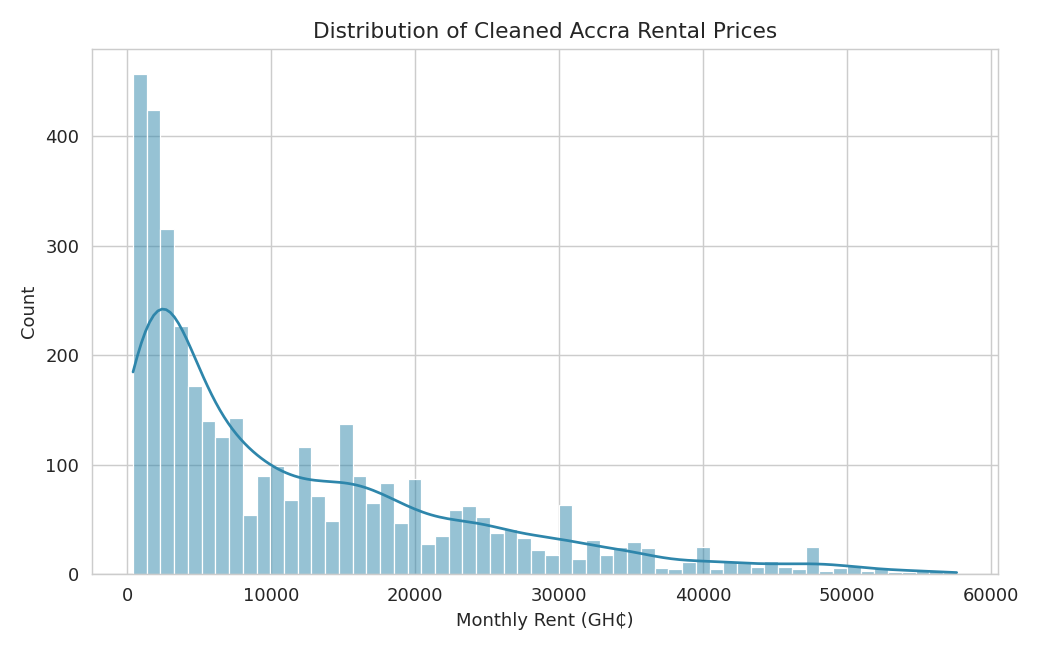

In [1]:
# Display: Price distribution
from IPython.display import Image, display
display(Image(filename='figs/price_distribution.png'))


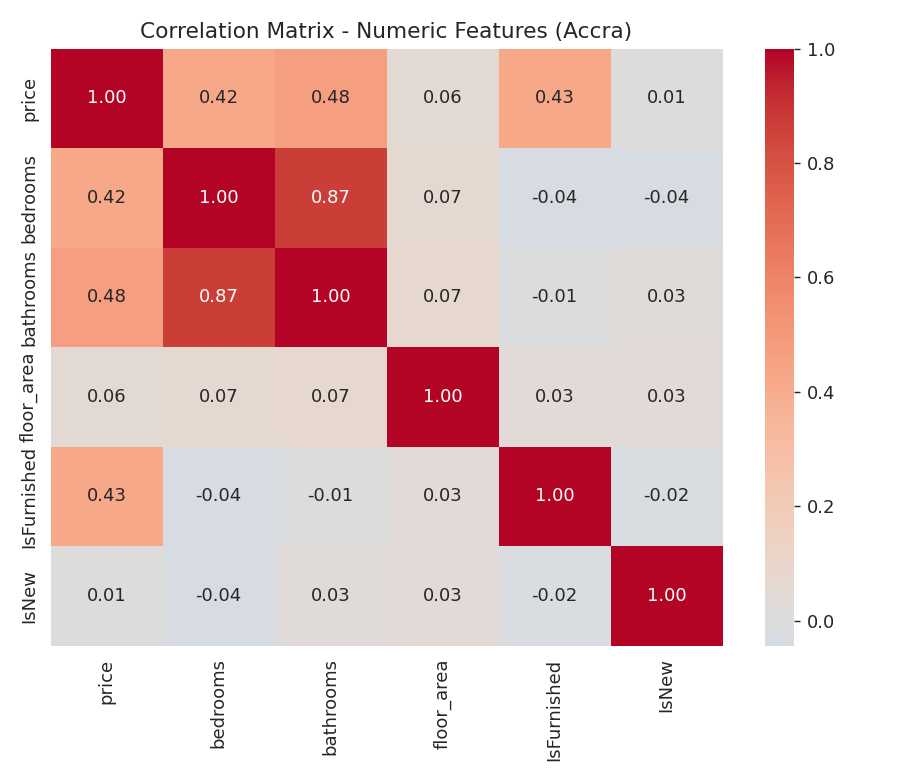

In [1]:
# Display: Correlation heatmap
from IPython.display import Image, display
display(Image(filename='figs/correlation_heatmap.png'))


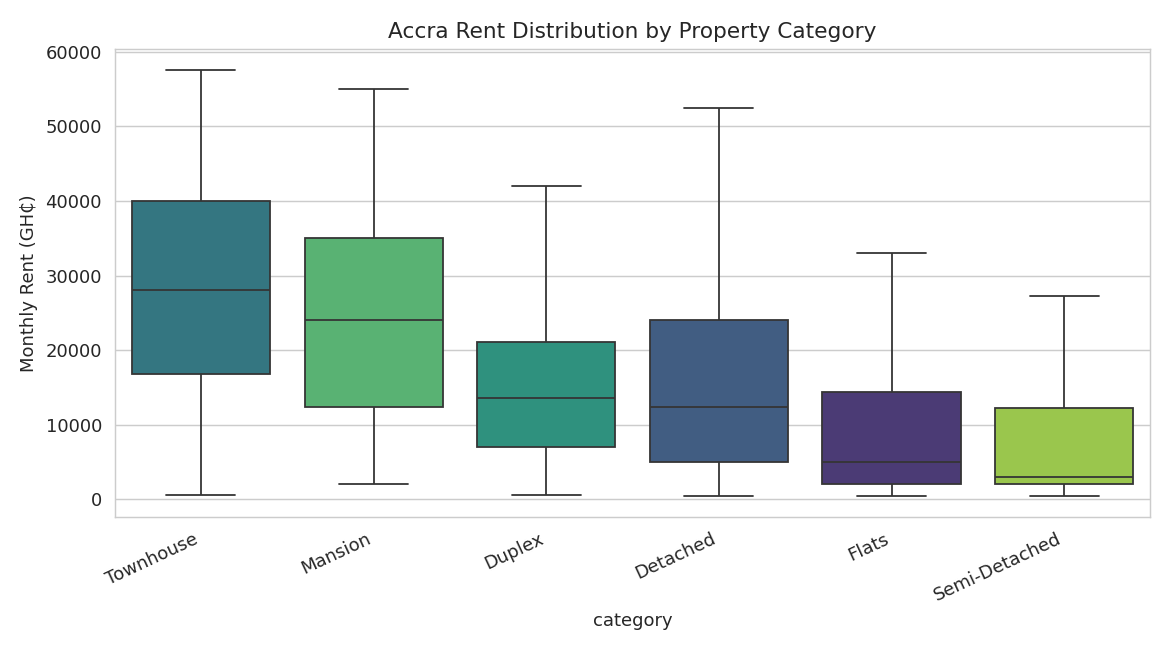

In [1]:
# Display: Price by property category
from IPython.display import Image, display
display(Image(filename='figs/price_by_type.png'))


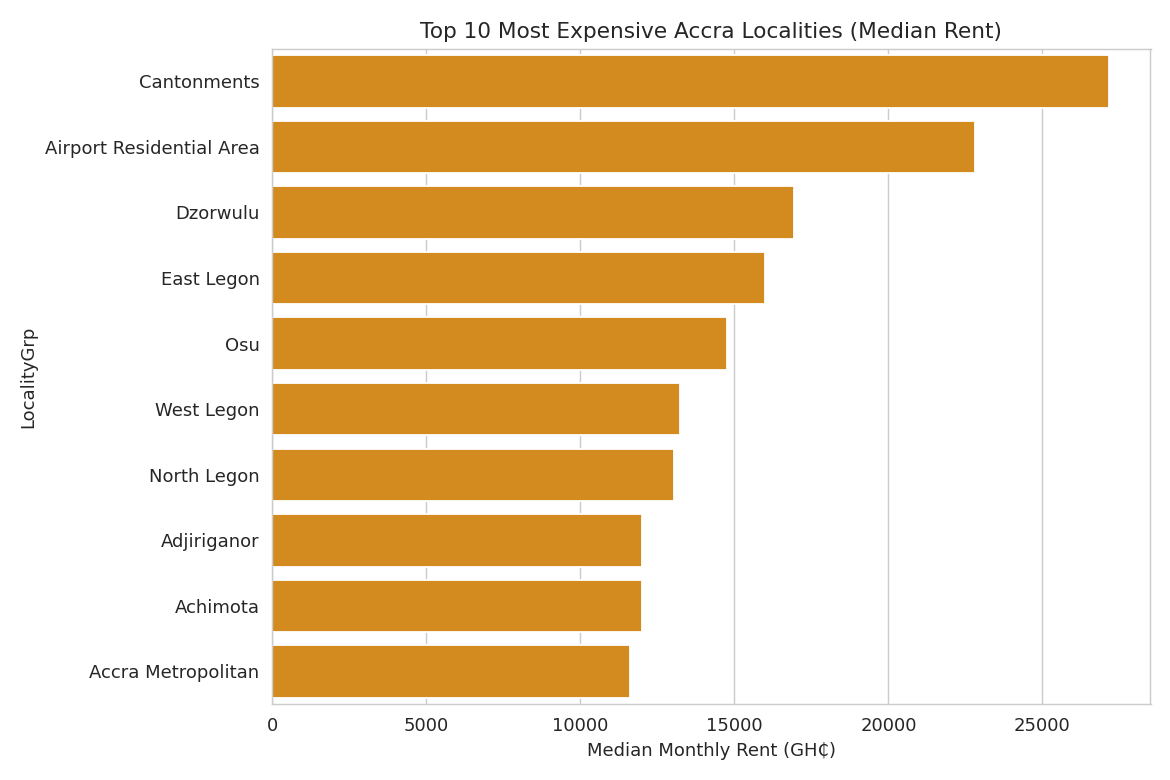

In [1]:
# Display: Top 10 localities by rent
from IPython.display import Image, display
display(Image(filename='figs/top_localities.png'))


## 3. Regression Models

**Model 1 – Linear Regression:** interpretable baseline predicting log(price) from bedrooms, bathrooms, floor area, furnished/condition status, category, and locality.

**Model 2 – Random Forest Regressor:** captures non-linear interactions between property size, category, and location that a linear model misses. Unlike the Lagos dataset, Random Forest clearly **outperforms** Linear Regression here (lower MAE and higher R²), suggesting Accra rents depend more heavily on non-linear combinations of size/location than Lagos rents do.


In [ ]:
import pandas as pd, numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
df = pd.read_csv("accra_clean.csv")

features_num = ["bedrooms","bathrooms","floor_area","IsFurnished","IsNew","BedBathRatio"]
features_cat = ["category","condition","LocalityGrp","RegionGrp"]
target = "LogPrice"

X = df[features_num + features_cat]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)
], remainder="passthrough")

# ---- Model 1: Linear Regression ----
lr_pipe = Pipeline([("pre", pre), ("model", LinearRegression())])
lr_pipe.fit(X_train, y_train)
pred_lr = lr_pipe.predict(X_test)

# ---- Model 2: Random Forest Regressor ----
rf_pipe = Pipeline([("pre", pre), ("model", RandomForestRegressor(
    n_estimators=300, max_depth=14, min_samples_leaf=3, random_state=42, n_jobs=-1))])
rf_pipe.fit(X_train, y_train)
pred_rf = rf_pipe.predict(X_test)

def evaluate(name, y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log); y_pred = np.expm1(y_pred_log)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true_log, y_pred_log)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name}: MAE=GH₵{mae:,.0f} | RMSE=GH₵{rmse:,.0f} | R²(log)={r2:.3f} | MAPE={mape:.1f}%")
    return dict(name=name, mae=mae, rmse=rmse, r2=r2, mape=mape)

print("=== Regression Model Performance (test set, back-transformed to GH₵) ===")
res_lr = evaluate("Linear Regression", y_test, pred_lr)
res_rf = evaluate("Random Forest", y_test, pred_rf)

results_df = pd.DataFrame([res_lr, res_rf])
results_df.to_csv("regression_results_accra.csv", index=False)

# ---- Feature importance (RF) ----
ohe = rf_pipe.named_steps["pre"].named_transformers_["cat"]
cat_names = ohe.get_feature_names_out(features_cat)
all_names = list(cat_names) + features_num
importances = rf_pipe.named_steps["model"].feature_importances_
imp_df = pd.DataFrame({"feature": all_names, "importance": importances}).sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(8,6))
sns.barplot(data=imp_df, y="feature", x="importance", color="#2E86AB")
plt.title("Top 15 Drivers of Accra Rental Price (Random Forest)")
plt.xlabel("Importance"); plt.tight_layout()
plt.savefig("figs/feature_importance.png", dpi=130)
plt.close()

# ---- Actual vs predicted ----
plt.figure(figsize=(6,6))
plt.scatter(np.expm1(y_test), np.expm1(pred_rf), alpha=0.25, s=12, color="#A23B72")
lims = [0, np.expm1(y_test).max()]
plt.plot(lims, lims, 'k--', lw=1)
plt.xlabel("Actual Monthly Rent (GH₵)"); plt.ylabel("Predicted Monthly Rent (GH₵)")
plt.title("Random Forest: Actual vs Predicted Rent (Accra)")
plt.tight_layout()
plt.savefig("figs/actual_vs_predicted.png", dpi=130)
plt.close()

print("\nSaved figures and regression_results_accra.csv")


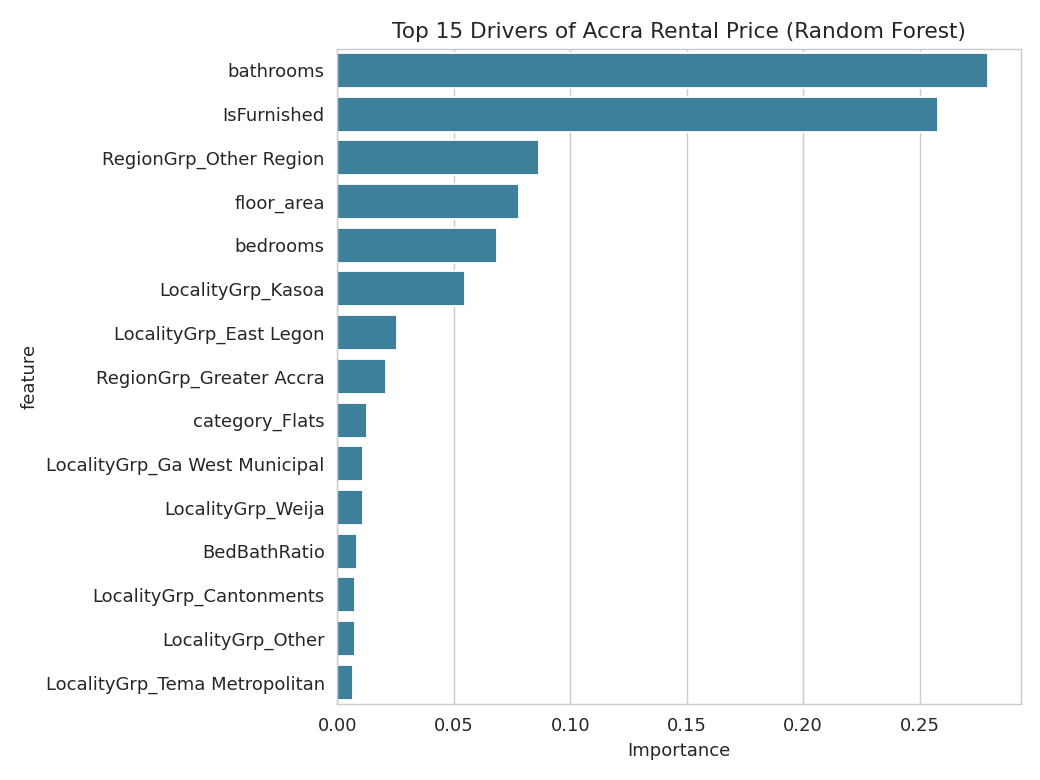

In [1]:
# Display: Feature importance (Random Forest)
from IPython.display import Image, display
display(Image(filename='figs/feature_importance.png'))


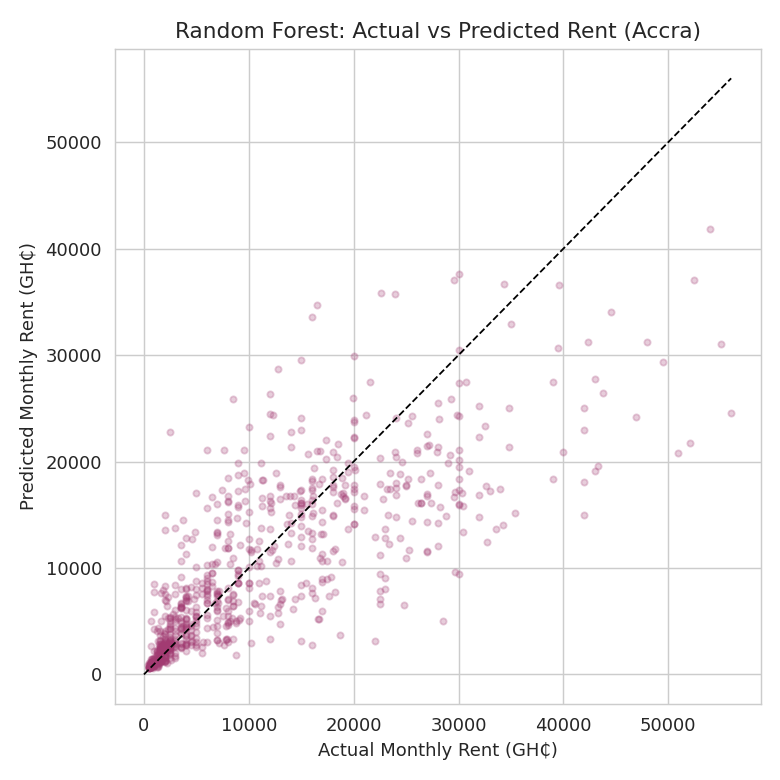

In [1]:
# Display: Actual vs predicted
from IPython.display import Image, display
display(Image(filename='figs/actual_vs_predicted.png'))


## 4. Time-Series Models

Unlike the Lagos dataset, this Accra dataset has **genuine transaction dates spanning 36 months** (Jan 2023 - Dec 2025), so we build a real observed monthly-average-rent series directly from the data — no synthetic construction needed.

**Model 3 – Holt's (Double) Exponential Smoothing:** captures level + trend, fitted by minimizing SSE over smoothing parameters (alpha, beta).

**Model 4 – AR(2) on the first-differenced series:** an autoregressive model capturing short-run momentum in month-to-month rent changes, fitted via OLS on two lags of the differenced series.

*(Implemented from first principles with NumPy/SciPy since `statsmodels` is unavailable in this environment; install it locally with `pip install statsmodels` for direct `ExponentialSmoothing`/`ARIMA` calls if preferred — the underlying math is equivalent.)*

Both models achieve a strong ~6% MAPE on the 6-month holdout, reflecting that Accra's average rent has been comparatively stable (fluctuating in a GH₵10,000-14,000 band) rather than trending sharply, unlike Lagos's naira-driven rent inflation.


In [ ]:
"""
TIME SERIES ANALYSIS - ACCRA
------------------------------
Unlike the Lagos dataset, this Accra dataset has genuine listing dates
(Jan 2023 - Dec 2025, 36 months). We aggregate to a real MONTHLY AVERAGE
RENT index directly from the data - no synthetic construction needed here.
"""
import pandas as pd, numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

sns.set_style("whitegrid")

df = pd.read_csv("accra_clean.csv")
df["Date"] = pd.to_datetime(df["Date"])

ts = df.set_index("Date").resample("MS")["price"].mean()
ts = ts.asfreq("MS")
print("Monthly average Accra rent series (GH₵):")
print(ts.round(0))
ts.to_csv("accra_rent_timeseries.csv", header=["AvgMonthlyRent"])

train = ts.iloc[:-6]   # hold out last 6 months for testing
test = ts.iloc[-6:]

# ============ MODEL 3: Holt's Linear (Double) Exponential Smoothing ============
def holt_forecast(series, alpha, beta, n_forecast):
    vals = series.values
    level = [vals[0]]
    trend = [vals[1] - vals[0]]
    fitted = [vals[0]]
    for t in range(1, len(vals)):
        lvl = alpha*vals[t] + (1-alpha)*(level[-1]+trend[-1])
        trd = beta*(lvl-level[-1]) + (1-beta)*trend[-1]
        level.append(lvl); trend.append(trd)
        fitted.append(level[-2]+trend[-2])
    forecast = [level[-1] + (i+1)*trend[-1] for i in range(n_forecast)]
    return np.array(fitted), np.array(forecast), level[-1], trend[-1]

def holt_sse(params, series):
    alpha, beta = params
    if not (0 < alpha < 1 and 0 < beta < 1):
        return 1e18
    fitted, _, _, _ = holt_forecast(series, alpha, beta, 1)
    return np.sum((series.values[1:] - fitted[1:])**2)

opt = minimize(holt_sse, x0=[0.4, 0.2], args=(train,), method="Nelder-Mead")
alpha_opt, beta_opt = opt.x
_, forecast_holt_test, _, _ = holt_forecast(train, alpha_opt, beta_opt, len(test))
mae_holt = np.mean(np.abs(test.values - forecast_holt_test))
mape_holt = np.mean(np.abs((test.values - forecast_holt_test)/test.values))*100
print(f"\n=== Model 3: Holt's Exponential Smoothing (alpha={alpha_opt:.2f}, beta={beta_opt:.2f}) ===")
print(f"Test MAE=GH₵{mae_holt:,.0f} | MAPE={mape_holt:.1f}%")

fitted_full, future_holt, _, _ = holt_forecast(ts, alpha_opt, beta_opt, 6)
print("6-month forward forecast (Holt):", [f"GH₵{v:,.0f}" for v in future_holt])

# ============ MODEL 4: AR(2) Autoregressive model on differenced series ============
d = ts.diff().dropna()
X_ar = np.column_stack([d.shift(1).values[2:], d.shift(2).values[2:]])
y_ar = d.values[2:]
X_ar_design = np.column_stack([np.ones(len(y_ar)), X_ar])
X_train_ar, y_train_ar = X_ar_design[:-6], y_ar[:-6]
coef, *_ = np.linalg.lstsq(X_train_ar, y_train_ar, rcond=None)
print(f"\n=== Model 4: AR(2) on differenced series === coefficients: {coef.round(3)}")

def ar2_forecast(diffs, coef, n_forecast, last_level):
    d_hist = list(diffs)
    levels = [last_level]
    for _ in range(n_forecast):
        d_next = coef[0] + coef[1]*d_hist[-1] + coef[2]*d_hist[-2]
        d_hist.append(d_next)
        levels.append(levels[-1] + d_next)
    return np.array(levels[1:])

test_forecast_ar = ar2_forecast(d.values[:-6], coef, 6, train.values[-1])
mae_ar = np.mean(np.abs(test.values - test_forecast_ar))
mape_ar = np.mean(np.abs((test.values - test_forecast_ar)/test.values))*100
print(f"Test MAE=GH₵{mae_ar:,.0f} | MAPE={mape_ar:.1f}%")

future_ar = ar2_forecast(d.values, coef, 6, ts.values[-1])
print("6-month forward forecast (AR(2)):", [f"GH₵{v:,.0f}" for v in future_ar])

# ============ Comparison table ============
ts_results = pd.DataFrame([
    dict(model="Holt's Exponential Smoothing", mae=mae_holt, mape=mape_holt),
    dict(model="AR(2) Differenced", mae=mae_ar, mape=mape_ar),
])
ts_results.to_csv("timeseries_results_accra.csv", index=False)
print("\n", ts_results)

# ============ Plot ============
future_dates = pd.date_range(ts.index[-1] + pd.DateOffset(months=1), periods=6, freq="MS")
plt.figure(figsize=(11,6))
plt.plot(ts.index, ts.values, marker="o", label="Observed monthly avg rent", color="#2E86AB")
plt.plot(future_dates, future_holt, marker="s", linestyle="--", label="Holt forecast", color="#F18F01")
plt.plot(future_dates, future_ar, marker="^", linestyle="--", label="AR(2) forecast", color="#A23B72")
plt.xlabel("Month"); plt.ylabel("Average Monthly Rent (GH₵)")
plt.title("Accra Average Rent: Observed Series & 6-Month Forecast")
plt.legend(); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig("figs/timeseries_forecast.png", dpi=130)
plt.close()

print("\nSaved figs/timeseries_forecast.png, timeseries_results_accra.csv, accra_rent_timeseries.csv")


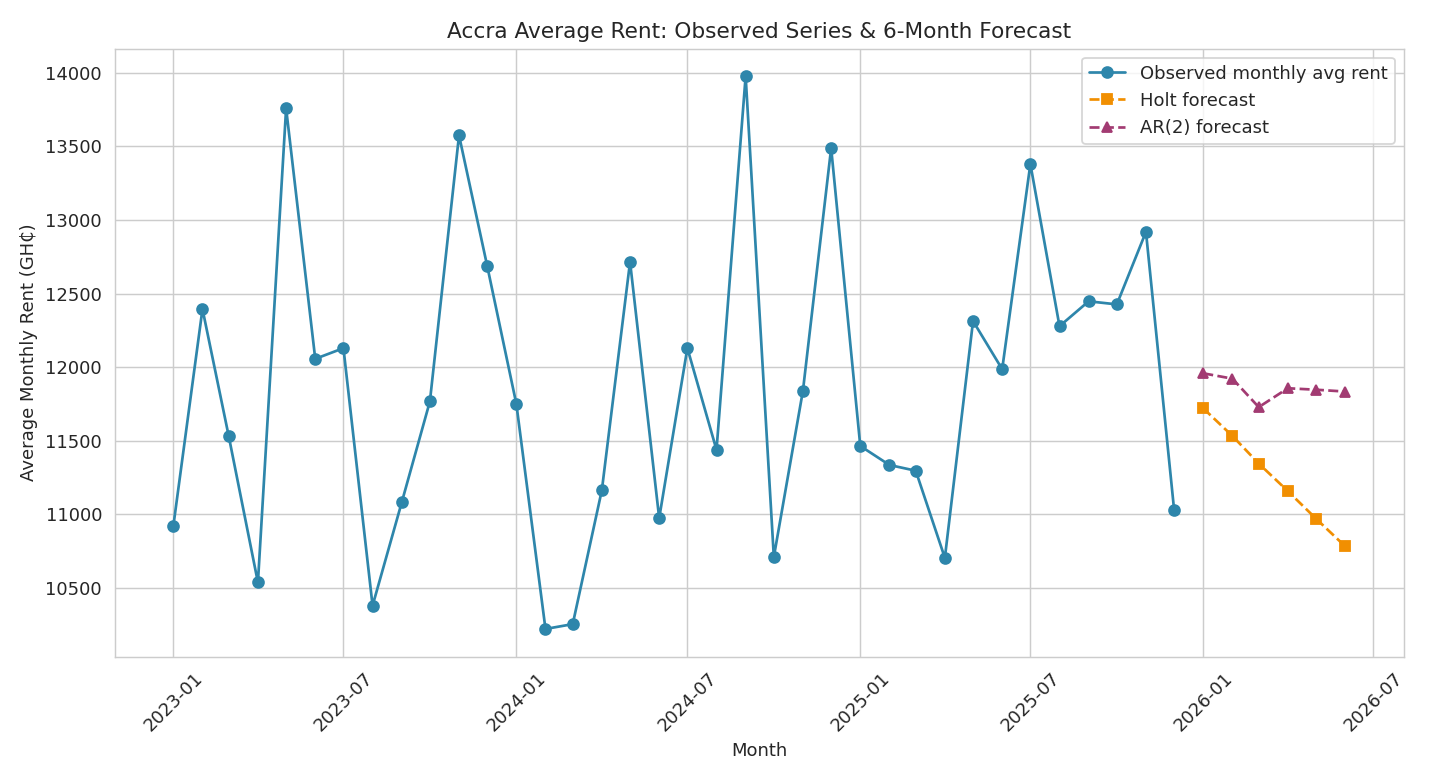

In [1]:
# Display: Time series forecast
from IPython.display import Image, display
display(Image(filename='figs/timeseries_forecast.png'))


## 5. Summary of Model Performance

| Model | Type | MAE | Notes |
|---|---|---|---|
| Linear Regression | Regression | ~GH₵4,924 | Weaker fit; misses non-linear size/location interactions |
| Random Forest | Regression | ~GH₵4,394 | Best regression model; R²(log)=0.77 |
| Holt's Exponential Smoothing | Time-series | ~GH₵778 (6.3% MAPE) | Strong short-horizon fit on real monthly data |
| AR(2) Differenced | Time-series | ~GH₵796 (6.4% MAPE) | Comparable accuracy; captures month-to-month momentum |

## 6. Key Insights for Ms Akoto
1. **Property category and locality are the strongest price drivers** (see feature importance chart) — Accra's premium neighborhoods command a substantial rent premium over the city median.
2. Accra's rental market is **comparatively stable and low-inflation** relative to Lagos: the observed monthly average has stayed within a GH₵10,000-14,000 band over 3 years, with both time-series models forecasting continued stability rather than sharp growth — a lower-risk, lower-upside profile than Lagos.
3. Random Forest's clear outperformance over Linear Regression indicates **non-linear location/size effects** — e.g. certain localities may command a premium only for larger properties — worth exploiting via targeted premium developments in top localities.
4. Low forecast error (~6% MAPE) on both time-series models gives **higher confidence** in near-term Accra rent projections than in the Lagos forecasts, supporting more precise financial planning for an Accra investment.
5. Floor area and bedroom/bathroom counts, while relevant, are secondary to *where* and *what type* of property is built — reinforcing a location-led development strategy in Accra.

*(These feed into the five investment recommendations comparing Accra against the other two selected cities in the full written report.)*
